# desilike vs our fitter on the run-1 samples, at several bin widths (exploratory)

**Question.** For every run-1 sample (Full, Fil, NonFil, Full diluted to N_Fil and to N_NonFil):
does desilike agree with our fitter, and what changes with the bin width of the monopole?

**Settings.** Everything you may want to change is in the next cell (bin widths `binseps`, fit range
`fit_range`, the Σ priors `Sigma_prior_sd` and `Sigma_free`, file locations) and is printed by it.
The covariance settings are read from `bao_fitting` (not repeated here) and printed too.
This text describes the method only: all numbers are in the cell outputs.

**Same inputs for both codes:** our ξ₀(s), our covariance (`gaussian_cov_pk` from the measured
spectra; the spectra do not depend on the binning, only the covariance sum does), MultiDark-Planck
cosmology (`bf.COSMO`), the same fit range.

**Three fits per sample and binning, in each code:**
* **α fit:** Gaussian prior on Σ, centred on Σ_th (the Zel'dovich prediction, section 1c) with width
  `Sigma_prior_sd`, as `run_all`. Gives α and its 68% interval.
* **Σ fit:** flat prior on Σ over `Sigma_free`, α free. Gives the best-fit Σ (profile). `run_all` quotes
  the *marginal* mean of Σ; desilike would need sampling (MCMC) for that, not done here.
* **no-wiggle fit:** same model without BAO. Δχ²_det = χ²(no-wiggle) − χ²(α fit, prior term included).

Not here: null-mock p-values and Δα/ΔΣ between samples (they stay in `run_all`).
The two random dilutions are fitted and listed in the tables and printouts, but left out of all plots.
A sample whose monopole file does not exist at a binning is skipped with a message.
Colours: blue = ours, orange = desilike. Nothing is written to disk.

In [1]:
import os, sys, warnings, time, inspect
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler

OURS, DESI, DATA = '#2a78d6', '#eb6834', '0.15'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
pk_file = os.path.join(REPO, 'data/processed/pk/box/pk_XISMU_box_mag-20.8_dist_fil.npz')
mono_sep = (5.0, 150.0)             # separation range of the monopole files [h^-1 Mpc] (in their names)
binseps = (5.0, 2.5)                # bin widths to compare [h^-1 Mpc]; binseps[0] = reference (bias, spectra plots)
fit_range = (50., 150.)             # [h^-1 Mpc]
Sigma_prior_sd = 2.0                # width of the Gaussian Sigma prior of the alpha fit (centred on Sigma_th)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit, as run_all
k_bao = 0.3                         # [h/Mpc] marked as the end of the BAO information in the plots (section 1c)

# sample -> label in the spectra file (= <bin_desc> of the monopole files written by the current script)
samples = {'Full': 'full',
           'Fil': '0.0leqd_mathrmfilleq3.0',
           'NonFil': '10.0leqd_mathrmfilleq100.0',
           'Full dil nFil': 'FullrandomN-559189r20261016',
           'Full dil nNonFil': 'FullrandomN-1003482r20261016'}

plot_samples = ['Full', 'Fil', 'NonFil']      # the dilutions appear in tables only
# -------------------------------------------------------------
bs_ref = binseps[0]

def monopole_file(key, binsep):
    # current naming ('leq') first, then the older one ('-'); None if neither exists
    for k in (key, key.replace('leqd', '-d')):
        f = os.path.join(MONO, f'mag=-20.8_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}_binsep={binsep:.1f}_{k}.npz')
        if os.path.exists(f):
            return f
    return None

C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']
spec = bf.load_spectra(pk_file)

# covariance and bias settings, read from bao_fitting so the plots always show what the code does
defaults = lambda f: {n: p.default for n, p in inspect.signature(f).parameters.items()
                      if p.default is not inspect.Parameter.empty}
cov_set, kmax_cov = defaults(bf.spectrum_for_cov), defaults(bf.gaussian_cov_pk)['kmax']
k_lo, k_hi, k_use = cov_set['k_lo'], cov_set['k_hi'], spec['kmax']   # k_use = end of the measured spectrum
b_set = defaults(bf.estimate_bias_independent)
bias_range = b_set['ranges'][b_set['primary']]

print(f"fit range {fit_range} h^-1 Mpc;  bin widths {binseps};  monopole files cover {mono_sep}")
print(f"alpha fit: Sigma ~ N({Sigma_th:.2f}, {Sigma_prior_sd:g}) [Sigma_th = Zel'dovich prediction];  "
      f"Sigma fit: flat {Sigma_free}")
print(f"covariance: bias from {bias_range} h^-1 Mpc;  P_cov = b^2 P_lin + N below k_lo = {k_lo}, measured above "
      f"k_hi = {k_hi} (N from k in {cov_set['n_win']}), measured spectrum up to k = {k_use:.3f} "
      f"({spec['n_fold']} foldings, each level to {spec['kuse_frac']} of its Nyquist), constant excess above, "
      f"modes summed to k = {kmax_cov}")
print(f"spectra labels: {spec['labels']}")

fit range (50.0, 150.0) h^-1 Mpc;  bin widths (5.0, 2.5);  monopole files cover (5.0, 150.0)
alpha fit: Sigma ~ N(7.78, 2) [Sigma_th = Zel'dovich prediction];  Sigma fit: flat (0.0, 16.0)
covariance: bias from (40, 70) h^-1 Mpc;  P_cov = b^2 P_lin + N below k_lo = 0.02, measured above k_hi = 0.025 (N from k in (0.1, 0.2)), measured spectrum up to k = 2.893 (2 foldings, each level to 0.6 of its Nyquist), constant excess above, modes summed to k = 3.0
spectra labels: ['full', '0.0leqd_mathrmfilleq3.0', '10.0leqd_mathrmfilleq100.0', 'FullrandomN-1043082r20261016', 'FullrandomN-2176035r20261016']


## 1. Data and covariance at each binning

For each sample: N, the number of bins in the fit range, and the bias b used in the covariance (fitted
over `bias_range`, printed above; it only enters the low-k part of the covariance). Then the monopoles at
each binning and their errors √diag(C) (bottom row).

What to expect: the per-bin error is dominated by cosmic variance (the same long-wavelength modes move
every bin, whatever its width), so it should barely change with the bin width; only the shot-noise part
grows, by ~√2 per halving of the width, so the change is largest for the sample with the most (excess)
shot noise.

Full               bin 5.0:  N =  4999875   20 bins in fit range   b(cov) = 0.978
Full               bin 2.5:  N =  4999875   40 bins in fit range   b(cov) = 0.978
Fil                bin 5.0:  N =  1043082   20 bins in fit range   b(cov) = 1.384
Fil                bin 2.5:  N =  1043082   40 bins in fit range   b(cov) = 1.384
WARNING bias estimate unstable across ranges: (30, 60): 0.608, (40, 70): 0.723, (35, 75): 0.675  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
NonFil             bin 5.0:  N =  2176035   20 bins in fit range   b(cov) = 0.723
WARNING bias estimate unstable across ranges: (30, 60): 0.607, (40, 70): 0.722, (35, 75): 0.674  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
NonFil             bin 2.5:  N =  2176035   40 bins in fit range   b(cov) = 0.722
SKIP Full dil nFil at 5.0: no monopole file (run scripts/multidark_analysis.py with bin_size_2d = 5.0)
SKIP Full

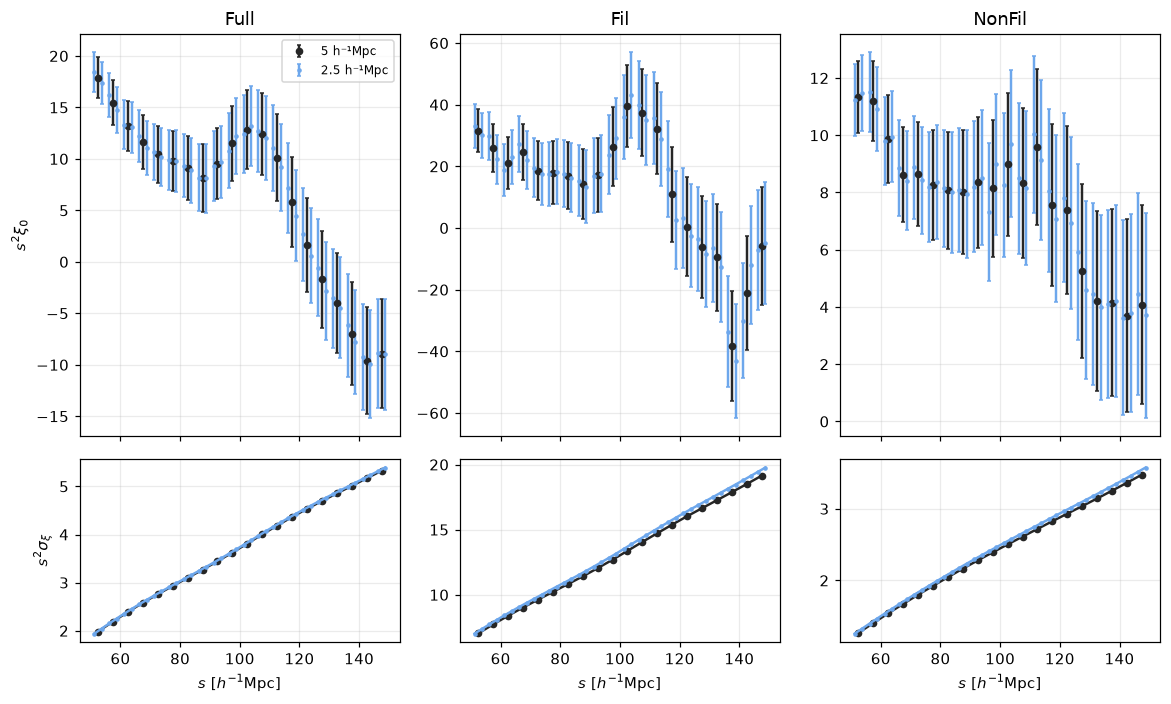

In [2]:
data = {}
for lab, key in samples.items():
    for bs in binseps:
        f = monopole_file(key, bs)
        if f is None:
            print(f"SKIP {lab} at {bs}: no monopole file (run scripts/multidark_analysis.py with bin_size_2d = {bs})")
            continue
        s, xi, n_gal = bf.load_monopole(f)
        edges = bf.edges_from_centres(s)
        assert edges[0] <= fit_range[0] and edges[-1] >= fit_range[1], \
            f"{lab} at {bs}: monopole covers {edges[0]}-{edges[-1]}, fit_range is {fit_range}"
        i_spec = spec['labels'].index(key)
        assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
        b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
        C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b], lin)
        m = (s >= fit_range[0]) & (s <= fit_range[1])
        data[lab, bs] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b)
        print(f"{lab:<18} bin {bs}:  N = {n_gal:>8d}   {m.sum():>2d} bins in fit range   b(cov) = {b:.3f}")

labs = [l for l in samples if any((l, bs) in data for bs in binseps)]     # all samples (tables)
labs_p = [l for l in labs if l in plot_samples]                              # plotted samples
fig, axes = plt.subplots(2, len(labs_p), figsize=(3.6 * len(labs_p), 6.5), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
for j, lab in enumerate(labs_p):
    for bs, mk, c in zip(binseps, ('o', '.'), ('0.15', '#6da7ec')):
        if (lab, bs) not in data: continue
        d = data[lab, bs]; s, m = d['s'], d['m']
        axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * d['sig'][m], fmt=mk, ms=4, capsize=1.5,
                            color=c, label=f'{bs:g} h⁻¹Mpc')
        axes[1, j].plot(s[m], s[m]**2 * d['sig'][m], mk + '-', ms=4, color=c)
    axes[0, j].set_title(lab); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$s^2\sigma_\xi$'); axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 1b. The measured power spectra, and what "excess noise" means

The covariance is built from these spectra (one auto-spectrum per sample, file `pk_file`). Colours here =
samples (not codes). The k values named below (k_lo, k_hi, k_use, k_bao) are printed in the setup cell.

**Left:** P(k) of each sample (solid), shot noise not subtracted. Dotted: b²P_lin(k), the linear-theory
prediction with the sample's bias. Dashed horizontal: the Poisson shot noise 1/n̄. For a Poisson sample of a
linear density field, P = b²P_lin + 1/n̄: the curve would follow the dotted line at low k and flatten onto
the dashed line at high k.

**Right:** the "excess" [P(k) − b²P_lin(k)] · n̄: everything in the measured power that linear theory does
not explain, in units of Poisson shot noise. For a Poisson sample of a linear field it would be exactly 1
at every k. Above 1 means extra power: non-linear clustering of small groups (galaxies sharing haloes) and,
for Fil, any extra clumpiness from how DisPerSE selects filament galaxies. In the covariance it acts like
extra noise, which is why we call it "excess noise". The spectra are measured up to k_use by
folding the box (`multidark_power.measure_spectra`): the positions are wrapped into a box of side L/2^f and
measured on the same grid, which gives exactly the modes of the full box that fit in L/2^f, and
P(k) = 8^f P_folded(k). Each fold level is used up to `kuse_frac` of its own Nyquist frequency, so no part
of the plotted spectrum is near a grid limit. The short dashed lines show the constant value the covariance
assumes beyond k_use (and up to infinite k), the measured excess averaged just below k_use.
Vertical dotted lines: k_lo (below it the covariance uses b²P_lin + N), the start of each fold level, and k_use.
Shaded: k < k_bao (section 1c).

Below k_hi the measured spectrum is used directly by the covariance, so any excess there (noise or extra
clustering) is not an assumption; the assumption is only the dashed tail. The printed table also lists the
two random dilutions: "Full dil nFil" has the same n̄ as Fil but randomly chosen galaxies, so comparing it
with Fil separates the effect of *which* galaxies are selected from the effect of *how many*.

sample               1/nbar  excess x nbar at k = 0.15, 0.3, 0.6, 1, 1.5, 2, 2.8   | value assumed above 2.89
Full                    200   2.07  2.54  2.12  1.76  1.51  1.38  1.25   |  1.26
Fil                     959  16.22 10.88  6.16  3.54  2.41  1.95  1.61   |  1.62
NonFil                  460   4.72  2.67  1.79  1.45  1.28  1.21  1.15   |  1.15


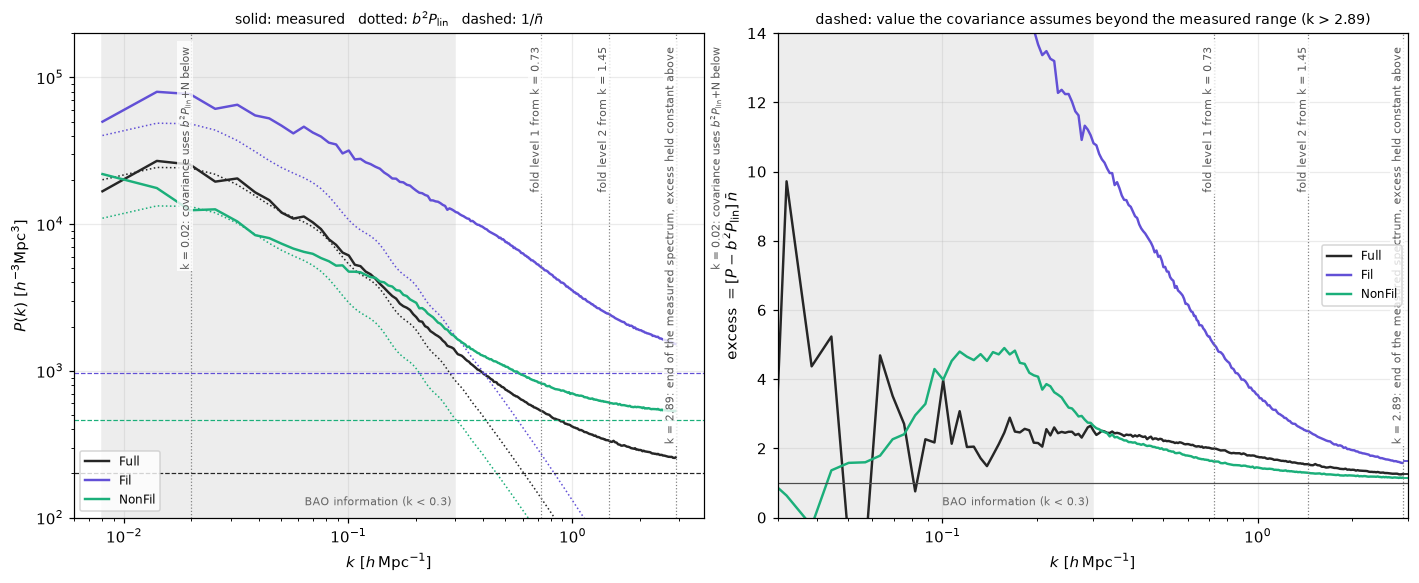

In [3]:
SCOL = {'Full': '0.15', 'Fil': '#6250d6', 'NonFil': '#1baf7a', 'Full dil nFil': '#eda100', 'Full dil nNonFil': '#e87ba4'}
kk = spec['k']
k_fold = [kk[spec['level'] == f][0] for f in range(1, spec['n_fold'] + 1)]   # start of each fold level
k_print = (0.15, 0.3, 0.6, 1.0, 1.5, 2.0, 2.8)
Plin = lambda x: np.exp(np.interp(np.log(x), np.log(lin['kh']), np.log(lin['pk'])))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.4))
print(f"{'sample':<18}{'1/nbar':>9}  excess x nbar at k = " + ", ".join(f"{x:g}" for x in k_print)
      + f"   | value assumed above {k_use:.2f}")
for lab, key in samples.items():
    if (lab, bs_ref) not in data: continue
    i = spec['labels'].index(key); nbar = spec['n_gal'][i] / bf.L_BOX**3; b = data[lab, bs_ref]['b']; c = SCOL[lab]
    P = spec['P'][i, i]
    ex = (P - b**2 * Plin(kk)) * nbar
    _, ex_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, np.array([0.5]))
    if lab in plot_samples:
        a1.loglog(kk, P, color=c, label=lab)
        a1.loglog(kk, b**2 * Plin(kk), color=c, ls=':', lw=1)
        a1.axhline(1 / nbar, color=c, ls='--', lw=0.8)
        a2.semilogx(kk, ex, color=c, label=lab)
        a2.hlines(ex_tail * nbar, k_use, kmax_cov, color=c, ls='--', lw=1.2)
    at = lambda x: np.interp(x, kk, ex)
    print(f"{lab:<18}{1/nbar:>9.0f}  " + " ".join(f"{at(x):5.2f}" for x in k_print) + f"   | {ex_tail * nbar:5.2f}")
vlines = ((k_lo, f'k = {k_lo}: covariance uses $b^2P_{{\\rm lin}}$+N below'),
          *[(x, f'fold level {f + 1} from k = {x:.2f}') for f, x in enumerate(k_fold)],
          (k_use, f"k = {k_use:.2f}: end of the measured spectrum, excess held constant above"))
for a in (a1, a2):
    a.axvspan(kk[0], k_bao, color='0.93', zorder=0)
    a.text(k_bao, 0.02, f'BAO information (k < {k_bao}) ', transform=a.get_xaxis_transform(), ha='right', va='bottom',
           fontsize=7, color='0.4')
    for x, txt in vlines:
        a.axvline(x, color='0.5', ls=':', lw=0.8)
        a.text(x, 0.98, txt + ' ', transform=a.get_xaxis_transform(), rotation=90, ha='right', va='top',
               fontsize=7, color='0.35', bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
    a.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a1.set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); a1.set_ylim(1e2, 2e5); a1.legend(fontsize=8, loc='lower left')
a1.set_title('solid: measured   dotted: $b^2P_{\\rm lin}$   dashed: $1/\\bar n$', fontsize=9)
a2.axhline(1, color='0.3', lw=0.8); a2.set_xlim(0.03, kmax_cov); a2.set_ylim(0, 14)
a2.set_ylabel(r'excess $=[P - b^2P_{\rm lin}]\,\bar n$'); a2.legend(fontsize=8, loc='center right')
a2.set_title(f"dashed: value the covariance assumes beyond the measured range (k > {k_use:.2f})", fontsize=9)
fig.tight_layout(); plt.show()

### The spectrum that actually enters the covariance

The plots above show the *measured* spectra. The covariance uses a patched version, P_cov(k), built by
`bf.spectrum_for_cov` and evaluated on the box's discrete modes (|k| = 2π|n|/L) up to `kmax_cov`. The
settings named here are arguments of `spectrum_for_cov` / `gaussian_cov_pk`; their values are printed in
the setup cell.

| k range | P_cov(k) | why |
|---|---|---|
| k < k_lo | b²P_lin(k) + N_low, with N_low = mean excess over `n_win` | few modes, measurement noisy |
| k_lo – k_hi | linear blend of the two | smooth transition |
| k_hi – k_use | the measured P(k) (folded at high k) | well measured |
| k_use – kmax_cov | b²P_lin(k) + N_tail, N_tail = mean excess just below k_use | beyond the measurement |
| > kmax_cov | constant N_tail (added analytically, Parseval) | — |

k_use is the end of the measured spectrum, set in `multidark_analysis.py` by `pk_ngrid`, `pk_n_fold` and
`pk_kuse_frac`: fold level f reaches kuse_frac · π ng 2^f / L. `kuse_frac` < 1 because near each level's
Nyquist frequency the measurement is affected by aliasing and the grid-assignment window.

Top row: measured spectrum (grey) and P_cov (colour) for each sample; shading marks the regions.
Bottom row: P_cov / P_measured where both exist. Ratios ≠ 1 show where the covariance is not using the
measurement.

**Why the measured P(k) is not used below k_lo.** The box contains only a few long-wavelength modes.
The power in each single mode fluctuates randomly by about 100% of its mean (that is the Gaussian property
the covariance formula itself uses), and the measured P(k) in a k bin is the average over the modes in that
bin, so its scatter is about 1/√N for N independent modes (k and −k are the same mode, so N is half the
number of grid modes). The cell below counts them from the spectra file.

The covariance needs the *expected* P(k) (the average over many universes), not this box's particular
random values, and P enters it squared, so a fractional fluctuation ε in P becomes ≈ 2ε in the covariance.
Where the scatter is large (below k_lo) the smooth model b²P_lin + N is used; above k_hi the measurement is
used directly; in between the two are blended. The model only enters where the data cannot pin down the
average.

In [4]:
nm = spec['nmodes']
print(f"k bin width = {kk[1] - kk[0]:.4f} h/Mpc")
print(f"{'k':>8}{'grid modes':>12}{'independent':>13}{'scatter 1/sqrt(N)':>19}")
for kx in (0.008, 0.02, 0.04, k_lo, k_hi, k_bao):
    i = np.argmin(abs(kk - kx))
    print(f"{kk[i]:>8.4f}{nm[i]:>12.0f}{nm[i] / 2:>13.0f}{1 / np.sqrt(nm[i] / 2):>19.3f}")

k bin width = 0.0060 h/Mpc
       k  grid modes  independent  scatter 1/sqrt(N)
  0.0080          18            9              0.333
  0.0197          98           49              0.143
  0.0385         450          225              0.067
  0.0197          98           49              0.143
  0.0255         210          105              0.098
  0.3016       29066        14533              0.008


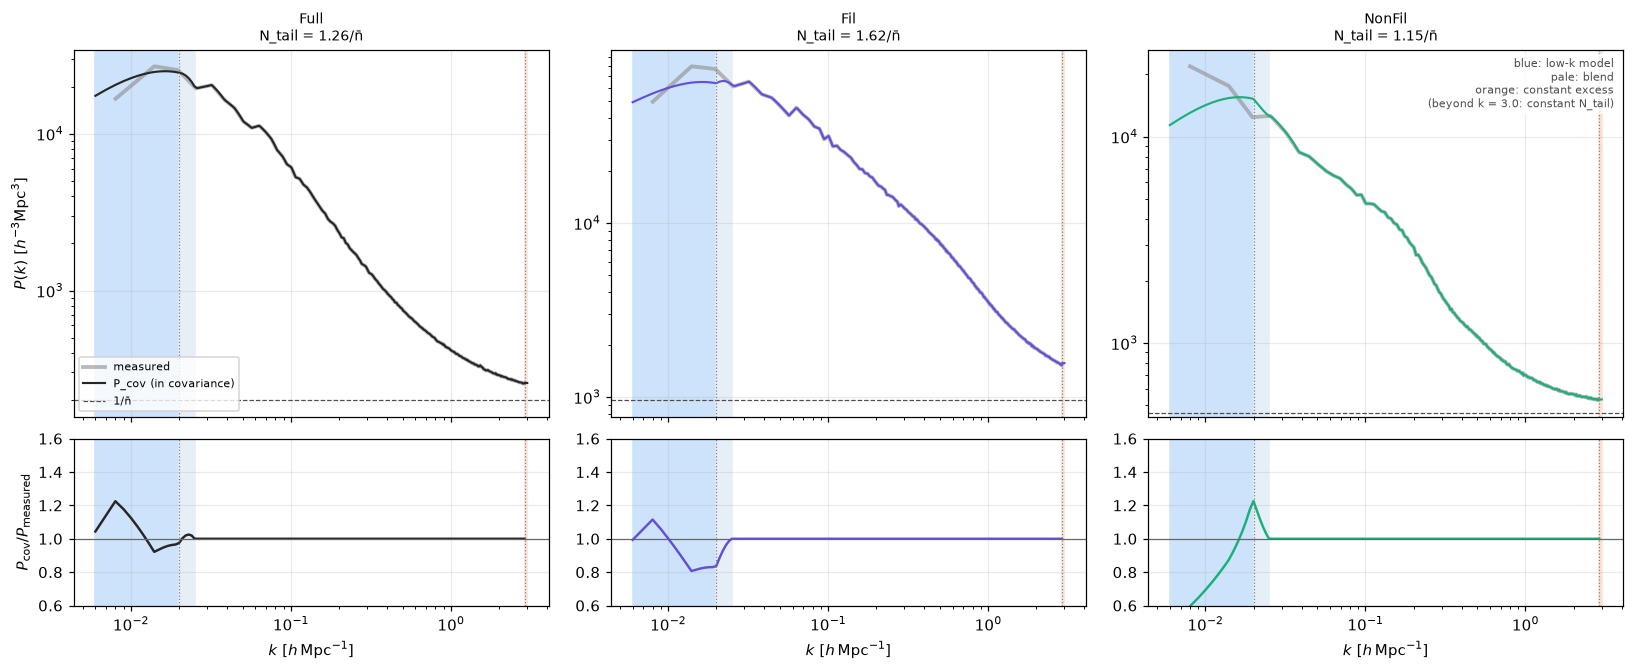

In [5]:
kgrid = np.linspace(0.006, kmax_cov, 3000)
labs_s = [l for l in plot_samples if (l, bs_ref) in data]
fig, axes = plt.subplots(2, len(labs_s), figsize=(5 * len(labs_s), 6.2), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
regions = ((0.006, k_lo, '#cde2fb'), (k_lo, k_hi, '#e6eef8'), (k_use, kmax_cov, '#fbe3d6'))
for j, lab in enumerate(labs_s):
    key = samples[lab]; i = spec['labels'].index(key); b = data[lab, bs_ref]['b']; c = SCOL[lab]
    Pcov, N_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, kgrid)
    P = spec['P'][i, i]
    ax, axr = axes[0, j], axes[1, j]
    for lo, hi, col in regions:
        ax.axvspan(lo, hi, color=col, zorder=0); axr.axvspan(lo, hi, color=col, zorder=0)
    ax.loglog(kk, P, color='0.55', lw=2.5, alpha=0.6, label='measured')
    ax.loglog(kgrid, Pcov, color=c, lw=1.4, label='P_cov (in covariance)')
    nbar = spec['n_gal'][i] / bf.L_BOX**3
    ax.axhline(1 / nbar, color='0.3', ls='--', lw=0.8, label='1/n̄')
    ax.set_title(f"{lab}\nN_tail = {N_tail * nbar:.2f}/n̄", fontsize=9)
    m_ = kgrid <= k_use
    axr.semilogx(kgrid[m_], Pcov[m_] / np.interp(kgrid[m_], kk, P), color=c)
    axr.axhline(1, color='0.4', lw=0.8); axr.set_ylim(0.6, 1.6); axr.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
    for x in (k_lo, k_use):
        ax.axvline(x, color='0.5', ls=':', lw=0.8); axr.axvline(x, color='0.5', ls=':', lw=0.8)
axes[0, 0].set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); axes[1, 0].set_ylabel(r'$P_{\rm cov}/P_{\rm measured}$')
axes[0, 0].legend(fontsize=7, loc='lower left')
axes[0, -1].text(0.98, 0.98, f'blue: low-k model\npale: blend\norange: constant excess\n(beyond k = {kmax_cov}: constant N_tail)',
                 transform=axes[0, -1].transAxes, ha='right', va='top', fontsize=7, color='0.3',
                 bbox=dict(fc='white', ec='none', alpha=0.8, pad=2))
fig.tight_layout(); plt.show()

## 1c. Where the BAO information lives (why the plots mark k_bao)

**The wiggles.** In Fourier space the BAO is the oscillation O(k) = P_lin/P_nw − 1, with period 2π/r_d
(r_d = sound horizon at the drag epoch). Its amplitude already decays with k in linear theory (Silk damping),
and non-linear motions multiply it by D(k) = exp(−k²Σ²/2), here with Σ = Σ_th. The cell prints D(k) and
the wiggle amplitude with and without damping at a few k.

**The peak width.** Multiplying by a Gaussian in k is the same as smoothing with a Gaussian of width Σ in s.
The cell prints the FWHM of the BAO bump s²(ξ − ξ_nw) of our template, undamped and with Σ = Σ_th.

**Information on α.** The standard Fourier-space (Seo & Eisenstein) Fisher information for α,
F(k_max) = V/(4π²) ∫₀^{k_max} k² dk [∂P/∂α / (P + 1/n̄)]², with ∂P/∂α = −b² k O′(k) D(k) P_nw (only the
wiggles are dilated), V = L³ the box volume and b the sample's bias. Middle panel: F(k_max)/F(∞); the cell
prints the fractions below a few k_max. Since it only counts the BAO wiggles, σ_α^Fisher = F(∞)^(−1/2) is a
lower limit for our fit with a free broadband; the two are compared below the summary table (section 5).

**What binning does.** Averaging j₀(ks) over a bin of width Δs multiplies each Fourier mode by about
sin(x)/x with x = kΔs/2 (right panel): 2/π at k = π/Δs and 0 at k = 2π/Δs. The cell prints these k and the
value at k_bao for each bin width. Halving Δs doubles both k, so finer bins add modes at high k, where the
BAO signal is negligible and the covariance relies on the high-k treatment of section 1b.

r_d = 100.07 h^-1 Mpc, wiggle period 2 pi / r_d = 0.0628 h/Mpc, Sigma_th = 7.78
     k      D(k)  |O| undamped  |O| damped
   0.1      0.74         0.067       0.056
   0.2       0.3         0.038       0.016
   0.3     0.066         0.014      0.0016
   0.4    0.0079        0.0038     6.2e-05
   0.6   1.9e-05       0.00026     1.4e-08
FWHM of the BAO bump s^2 (xi - xi_nw): 19.2 h^-1 Mpc undamped, 25.2 with Sigma_th
bin width 5: sin(x)/x = 0.91 at k_bao = 0.3, 2/pi at k = pi/ds = 0.63, 0 at k = 2 pi/ds = 1.26
bin width 2.5: sin(x)/x = 0.98 at k_bao = 0.3, 2/pi at k = pi/ds = 1.26, 0 at k = 2 pi/ds = 2.51
Full: fraction of the alpha information from k < 0.15: 0.581
Full: fraction of the alpha information from k < 0.2: 0.873
Full: fraction of the alpha information from k < 0.3: 0.998
Fil: fraction of the alpha information from k < 0.15: 0.610
Fil: fraction of the alpha information from k < 0.2: 0.891
Fil: fraction of the alpha information from k < 0.3: 0.998


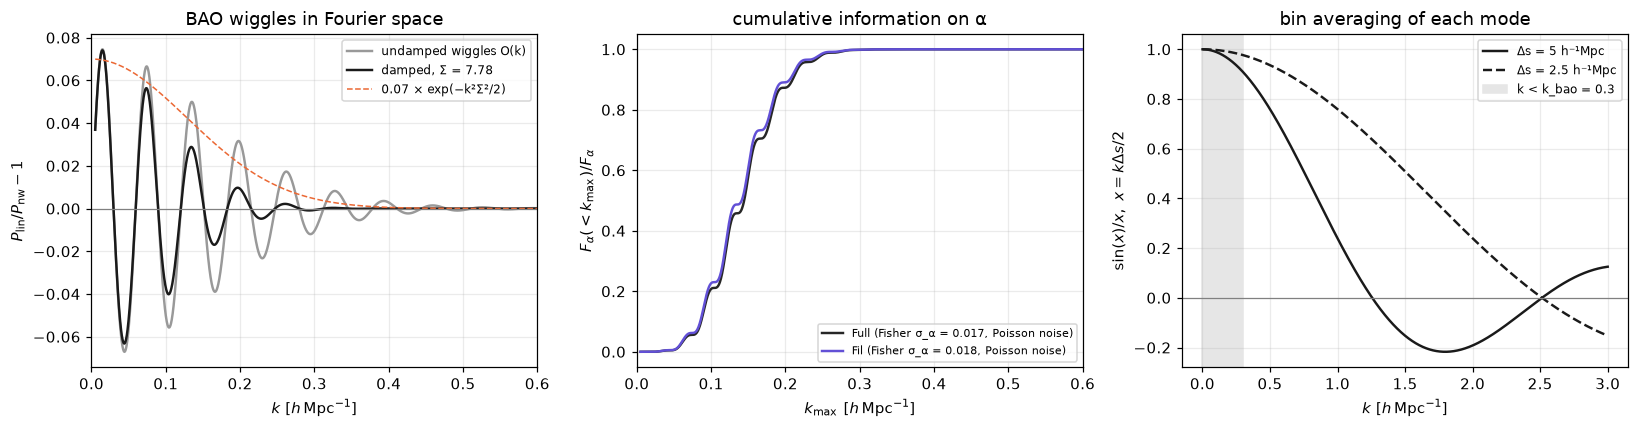

In [6]:
S_, rd_ = Sigma_th, lin['rd']
kf = np.linspace(0.005, 1.0, 4000)
Pl_, Pn_ = np.interp(kf, k, P_w), np.interp(kf, k, P_nw)
O_ = Pl_ / Pn_ - 1; D_ = np.exp(-kf**2 * S_**2 / 2)
fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(15, 4))
# numbers quoted in the text above
half = np.pi / rd_                                               # half a wiggle period
env = lambda y, kx: np.abs(y[(kf > kx - half) & (kf < kx + half)]).max()
print(f"r_d = {rd_:.2f} h^-1 Mpc, wiggle period 2 pi / r_d = {2 * np.pi / rd_:.4f} h/Mpc, Sigma_th = {S_:.2f}")
print(f"{'k':>6}{'D(k)':>10}{'|O| undamped':>14}{'|O| damped':>12}")
for kx in (0.1, 0.2, 0.3, 0.4, 0.6):
    print(f"{kx:>6}{np.exp(-kx**2 * S_**2 / 2):>10.2g}{env(O_, kx):>14.2g}{env(O_ * D_, kx):>12.2g}")
sg = np.arange(60., 140.01, 0.1)
def fwhm(S):
    y = sg**2 * T.xi_wig(S, s=sg); i0 = np.argmax(y); h = y[i0] / 2
    return sg[i0 + np.argmax(y[i0:] < h)] - sg[i0 - np.argmax(y[i0::-1] < h)]
print(f"FWHM of the BAO bump s^2 (xi - xi_nw): {fwhm(0.):.1f} h^-1 Mpc undamped, {fwhm(S_):.1f} with Sigma_th")
for ds in binseps:
    print(f"bin width {ds:g}: sin(x)/x = {np.sinc(k_bao * ds / 2 / np.pi):.2f} at k_bao = {k_bao}, "
          f"2/pi at k = pi/ds = {np.pi / ds:.2f}, 0 at k = 2 pi/ds = {2 * np.pi / ds:.2f}")
sig_fisher = {}

a0.plot(kf, O_, color='0.6', label='undamped wiggles O(k)')
a0.plot(kf, O_ * D_, color='0.1', label=f'damped, Σ = {S_:.2f}')
a0.plot(kf, 0.07 * D_, color='#eb6834', ls='--', lw=1, label='0.07 × exp(−k²Σ²/2)')
a0.axhline(0, color='0.5', lw=0.8); a0.set_xlim(0, 0.6); a0.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a0.set_ylabel(r'$P_{\rm lin}/P_{\rm nw}-1$'); a0.legend(fontsize=8); a0.set_title('BAO wiggles in Fourier space')
for lab in ('Full', 'Fil'):
    i = spec['labels'].index(samples[lab]); nbar = spec['n_gal'][i] / bf.L_BOX**3; b2 = data[lab, bs_ref]['b']**2
    dPda = -kf * np.gradient(O_, kf) * D_ * Pn_ * b2
    Ptot = b2 * Pn_ * (1 + O_ * D_) + 1 / nbar
    F = np.cumsum(kf**2 * (dPda / Ptot)**2) * (kf[1] - kf[0]) * bf.L_BOX**3 / (4 * np.pi**2)
    sig_fisher[lab] = 1 / np.sqrt(F[-1])
    a1.plot(kf, F / F[-1], color=SCOL[lab], label=f'{lab} (Fisher σ_α = {sig_fisher[lab]:.3f}, Poisson noise)')
    for km in (0.15, 0.2, 0.3):
        print(f"{lab}: fraction of the alpha information from k < {km}: {F[np.searchsorted(kf, km)] / F[-1]:.3f}")
a1.set_xlim(0, 0.6); a1.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$F_\alpha(<k_{\max})/F_\alpha$')
a1.legend(fontsize=7); a1.set_title('cumulative information on α')
kb = np.linspace(1e-3, 3, 2000)
for ds, ls in zip(binseps, ('-', '--')):
    a2.plot(kb, np.sinc(kb * ds / 2 / np.pi), color='0.1', ls=ls, label=f'Δs = {ds:g} h⁻¹Mpc')
a2.axvspan(0, k_bao, color='0.9', zorder=0, label=f'k < k_bao = {k_bao}')
a2.axhline(0, color='0.5', lw=0.8); a2.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a2.set_ylabel(r'$\sin(x)/x,\ x = k\Delta s/2$'); a2.legend(fontsize=8); a2.set_title('bin averaging of each mode')
fig.tight_layout(); plt.show()

### Where Σ_th comes from

Σ is the typical distance by which two galaxies that started r_d apart have moved *relative to each other*
since early times. That relative motion smears the BAO peak. It is computed from linear theory with the
Zel'dovich approximation (ESW07 §4–5; Chen+24 eq. 9), in `bf.sigma_nl_theory`.

1. **Displacement field.** In the Zel'dovich approximation each galaxy moves by Ψ(q), with
   Ψ(k) = i k δ(k)/k² in Fourier space (the gradient of the linear potential). So the power spectrum of each
   Cartesian component is P_lin(k)/k² times the square of that component's direction cosine.
2. **One galaxy.** The variance of one component of the displacement of a single galaxy is
   σ₁² = (1/3) ∫ d³k/(2π)³ P_lin(k)/k² = (1/3) ∫ dk/(2π²) P_lin(k).
3. **Two galaxies a distance r apart.** Long waves (k ≪ 1/r) move both together and cancel in the
   difference; short waves move them independently. Averaged over directions, the variance per component of
   Ψ(x) − Ψ(x + r) is

   **Σ² = (2/3) ∫₀^∞ dk/(2π²) P_lin(k) [1 − j₀(k r)]**,  with j₀(x) = sin x / x and r = r_d.

   The factor 1 − j₀(k r_d) is ≈ 0 for k ≪ 1/r_d and → 1 for k ≫ 1/r_d. (Along and across the separation the
   two components differ by ± j₂ terms; their monopole average leaves only the j₀ term.)
4. **Numbers.** The cell evaluates this with the MultiDark-Planck P_lin at z = 0 and prints Σ_th, σ₈ and σ₁.
   Σ² is proportional to the amplitude of P_lin, so Σ scales linearly with σ₈. For r → ∞, j₀ → 0 and
   Σ → √2 σ₁: a single-galaxy estimate (σ₁) is too small by √2.

Left: the integrand per ln k, dΣ²/d ln k = (2/3) k P_lin(k) [1 − j₀(k r_d)]/(2π²), and the same without the
[1 − j₀] factor (dotted). Right: Σ accumulated up to k_max. The cell prints the fraction of Σ² from very
large scales (k < 0.02, which move both galaxies together), from 0.02 < k < k_bao (large-scale flows, where
linear theory is reliable) and from k > k_bao (where it is less so; one reason the α fit uses a Gaussian
prior of width `Sigma_prior_sd` around Σ_th rather than a fixed value).

r_d = 100.07 h^-1 Mpc,  sigma_8 = 0.8228
Sigma (pairwise, this cell) = 7.779   bf.sigma_nl_theory = 7.779 h^-1 Mpc
sigma_1 (one galaxy, per axis) = 5.961;  sqrt(2) sigma_1 = 8.430 (pairwise limit for r -> infinity)
  Sigma from k < 0.02: 1.81
  Sigma from k < 0.05: 4.63
  Sigma from k < 0.1 : 6.05
  Sigma from k < 0.2 : 6.94
  Sigma from k < 0.3 : 7.26
  Sigma from k < 0.5 : 7.51
fraction of Sigma^2 from k < 0.02: 0.05;  0.02 < k < k_bao = 0.3: 0.82;  k > k_bao: 0.13


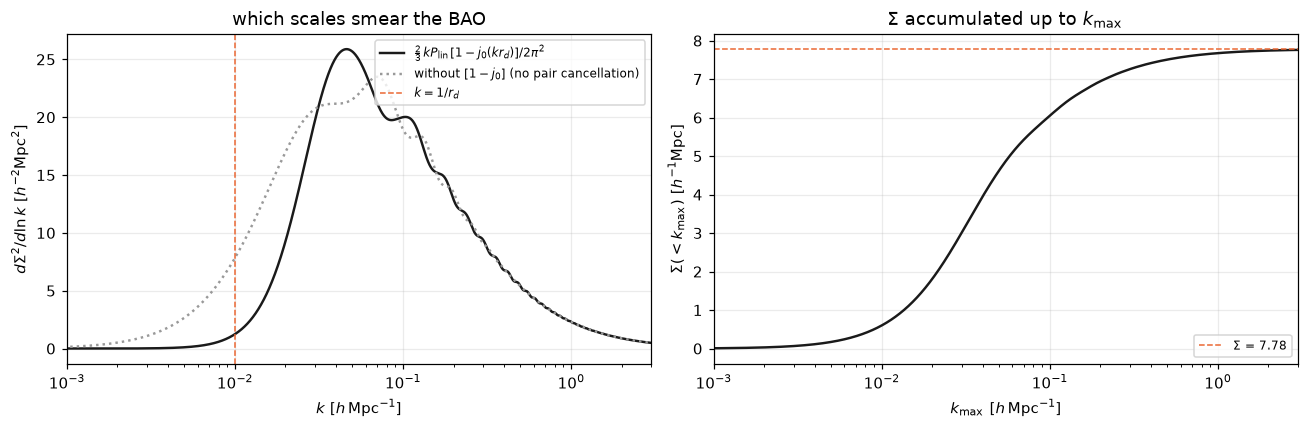

In [7]:
kh, Pk, rd = lin['kh'], lin['pk'], lin['rd']
j0 = np.sinc(kh * rd / np.pi)
dS2_dlnk = (2. / 3.) * kh * Pk * (1. - j0) / (2 * np.pi**2)          # integrand per ln k
dS2_dlnk_one = (2. / 3.) * kh * Pk / (2 * np.pi**2)                    # same without the pair factor
lnk = np.log(kh)
S2_cum = np.concatenate([[0.], np.cumsum(0.5 * (dS2_dlnk[1:] + dS2_dlnk[:-1]) * np.diff(lnk))])
Sigma_calc = np.sqrt(S2_cum[-1])
sigma1 = np.sqrt(np.trapezoid(Pk, kh) / (3 * 2 * np.pi**2))
print(f"r_d = {rd:.2f} h^-1 Mpc,  sigma_8 = {lin['sigma8']:.4f}")
print(f"Sigma (pairwise, this cell) = {Sigma_calc:.3f}   bf.sigma_nl_theory = {Sigma_th:.3f} h^-1 Mpc")
print(f"sigma_1 (one galaxy, per axis) = {sigma1:.3f};  sqrt(2) sigma_1 = {np.sqrt(2) * sigma1:.3f} (pairwise limit for r -> infinity)")
for km in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5):
    print(f"  Sigma from k < {km:<4}: {np.sqrt(np.interp(np.log(km), lnk, S2_cum)):.2f}")
fS2 = lambda km: np.interp(np.log(km), lnk, S2_cum) / S2_cum[-1]
print(f"fraction of Sigma^2 from k < 0.02: {fS2(0.02):.2f};  0.02 < k < k_bao = {k_bao}: "
      f"{fS2(k_bao) - fS2(0.02):.2f};  k > k_bao: {1 - fS2(k_bao):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.semilogx(kh, dS2_dlnk, color='0.1', label=r'$\frac{2}{3}\,k P_{\rm lin}\,[1-j_0(k r_d)]/2\pi^2$')
a1.semilogx(kh, dS2_dlnk_one, color='0.6', ls=':', label='without $[1-j_0]$ (no pair cancellation)')
a1.axvline(1 / rd, color='#eb6834', ls='--', lw=1, label=r'$k = 1/r_d$')
a1.set_xlim(1e-3, 3); a1.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$d\Sigma^2/d\ln k\ [h^{-2}{\rm Mpc}^2]$')
a1.legend(fontsize=8); a1.set_title('which scales smear the BAO')
a2.semilogx(kh, np.sqrt(S2_cum), color='0.1')
a2.axhline(Sigma_th, color='#eb6834', ls='--', lw=1, label=f'Σ = {Sigma_th:.2f}')
a2.set_xlim(1e-3, 3); a2.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a2.set_ylabel(r'$\Sigma(<k_{\max})\ [h^{-1}{\rm Mpc}]$')
a2.legend(fontsize=8); a2.set_title('Σ accumulated up to $k_{\\max}$')
fig.tight_layout(); plt.show()

## 2. The fits

desilike settings as in `desilike_test_full.ipynb`: real space (`dbeta` = 0, `sigmas` = 0),
isotropic damping (`sigmapar` = `sigmaper`), broadband a₀ + a₁/s + a₂/s², Wallisch no-wiggle
(`with_now='wallish2018'`), model averaged over each data bin (`wmatrix={'resolution': 10}`),
Minuit. Ours: `bf.fit_bao`, what `run_all` calls. Takes a few minutes (each desilike fit
recomputes its template).

In [8]:
def desilike_lik(d, bs, prior='gauss', only_now=False):
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=Sigma_prior_sd, limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], bs)}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open, as bf.fit_bao does
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

res = {}
t0 = time.time()
for (lab, bs), d in data.items():
    s, xi, C, e = d['s'], d['xi'], d['C'], d['edges']
    kw = dict(T=T, fit_range=fit_range, Sigma_theory=Sigma_th, s_edges=e)
    o_a = bf.fit_bao(s, xi, C, Sigma_prior=('gauss', 'theory', Sigma_prior_sd), **kw)
    o_S = bf.fit_bao(s, xi, C, Sigma_prior=('flat',) + Sigma_free, **kw)
    lik_a, obs_a = desilike_lik(d, bs, 'gauss'); d_a = desilike_fit(lik_a, interval=True)
    lik_S, _ = desilike_lik(d, bs, 'flat');      d_S = desilike_fit(lik_S)
    lik_n, obs_n = desilike_lik(d, bs, only_now=True); d_n = desilike_fit(lik_n)
    lik_a(**d_a['pars']); model_a = np.array(obs_a.flattheory)
    prior_term = ((d_a['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2
    res[lab, bs] = dict(ours=o_a, ours_S=o_S, des=d_a, des_S=d_S, des_nw=d_n, lik_a=lik_a, model_d=model_a,
                        model_o=bf.best_models(o_a, s, e)[0],
                        det_d=d_n['chi2'] - d_a['chi2'] - prior_term, chi2_d=d_a['chi2'] + prior_term)
    print(f"{lab:<18} bin {bs}: alpha ours {o_a['alpha']:.4f}  desilike {d_a['pars']['qiso']:.4f}   "
          f"({time.time() - t0:.0f} s)")

Full               bin 5.0: alpha ours 0.9790  desilike 0.9781   (12 s)
Full               bin 2.5: alpha ours 0.9780  desilike 0.9771   (26 s)
Fil                bin 5.0: alpha ours 0.9816  desilike 0.9811   (37 s)
Fil                bin 2.5: alpha ours 0.9811  desilike 0.9805   (51 s)
NonFil             bin 5.0: alpha ours 0.9544  desilike 0.9552   (64 s)
NonFil             bin 2.5: alpha ours 0.9513  desilike 0.9517   (79 s)


## 3. Best fits, one figure per bin width

Data with errors, both codes' best α-fit models, and normalised residuals (ξ − model)/σ.
The bins are correlated, so runs of same-sign residuals are expected and are not by themselves a sign of a
bad fit; the χ² in section 5 accounts for the correlations.

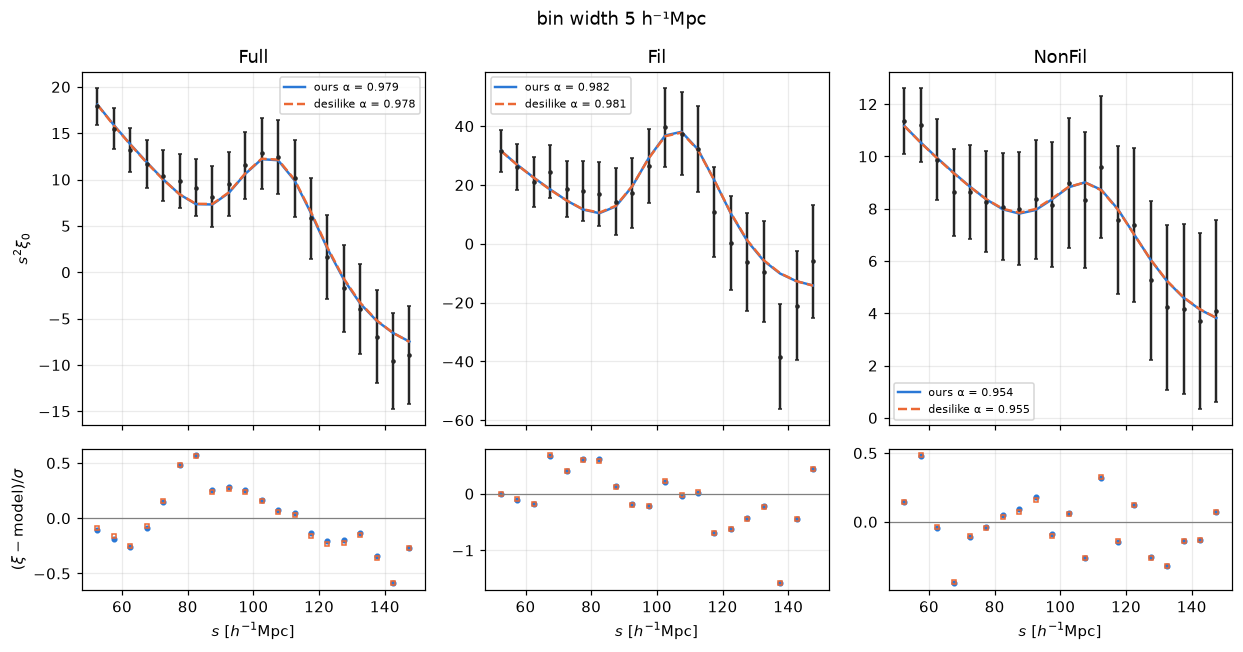

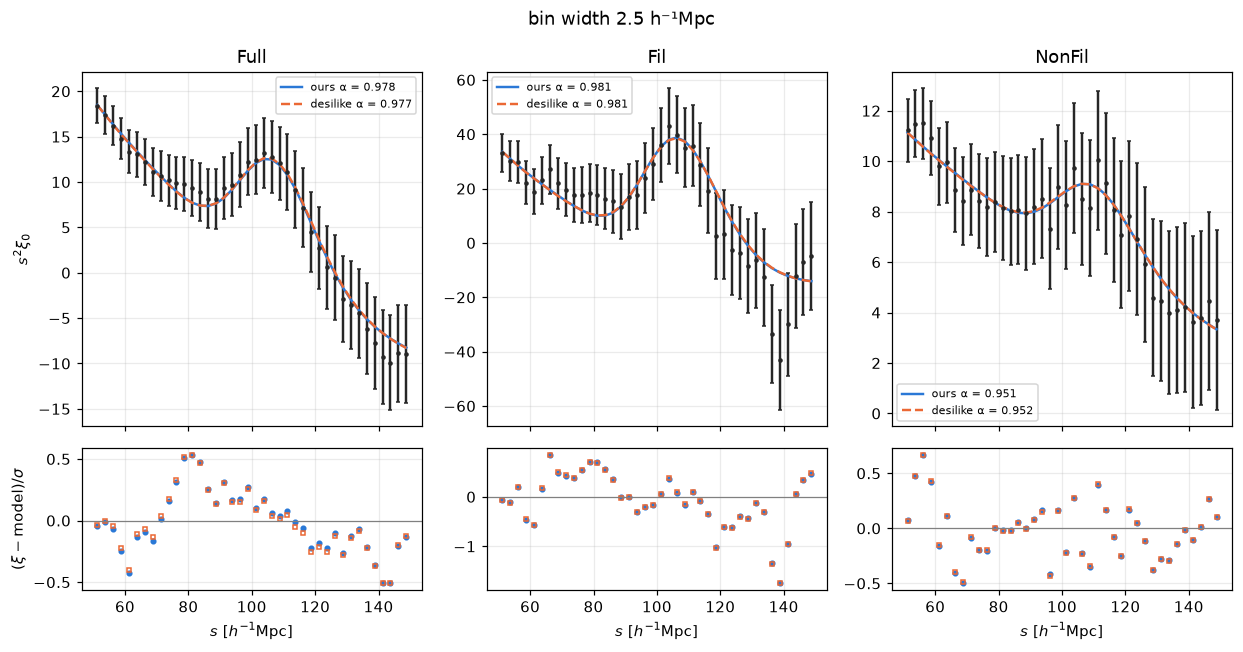

In [9]:
for bs in binseps:
    labs_b = [l for l in plot_samples if (l, bs) in res]
    fig, axes = plt.subplots(2, len(labs_b), figsize=(3.8 * len(labs_b), 6), sharex=True,
                             gridspec_kw=dict(height_ratios=(2.5, 1)), squeeze=False)
    for j, lab in enumerate(labs_b):
        d, r = data[lab, bs], res[lab, bs]; s, m, sg = d['s'], d['m'], d['sig']
        axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * sg[m], fmt='.', ms=4, capsize=1.5, color=DATA)
        axes[0, j].plot(s[m], s[m]**2 * r['model_o'][m], color=OURS, label=f"ours α = {r['ours']['alpha']:.3f}")
        axes[0, j].plot(s[m], s[m]**2 * r['model_d'], color=DESI, ls='--', label=f"desilike α = {r['des']['pars']['qiso']:.3f}")
        axes[1, j].plot(s[m], (d['xi'][m] - r['model_o'][m]) / sg[m], 'o', ms=3, color=OURS)
        axes[1, j].plot(s[m], (d['xi'][m] - r['model_d']) / sg[m], 's', ms=3, mfc='none', color=DESI)
        axes[1, j].axhline(0, color='0.5', lw=0.8); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
        axes[0, j].set_title(lab); axes[0, j].legend(fontsize=7)
    axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$(\xi-{\rm model})/\sigma$')
    fig.suptitle(f'bin width {bs:g} h⁻¹Mpc')
    fig.tight_layout(); plt.show()

## 4. χ²(α) profiles, all bin widths, both codes

Δχ² relative to each curve's minimum; dotted line Δχ² = 1. Line styles: solid = `binseps[0]`, dashed =
`binseps[1]`. If the binnings carry the same information, the curves have the same width (they can be
shifted: the binnings are not the same numbers, so α can move within its error). A curve that stays below
Δχ² = 1 over the whole α range means α is not constrained for that sample.

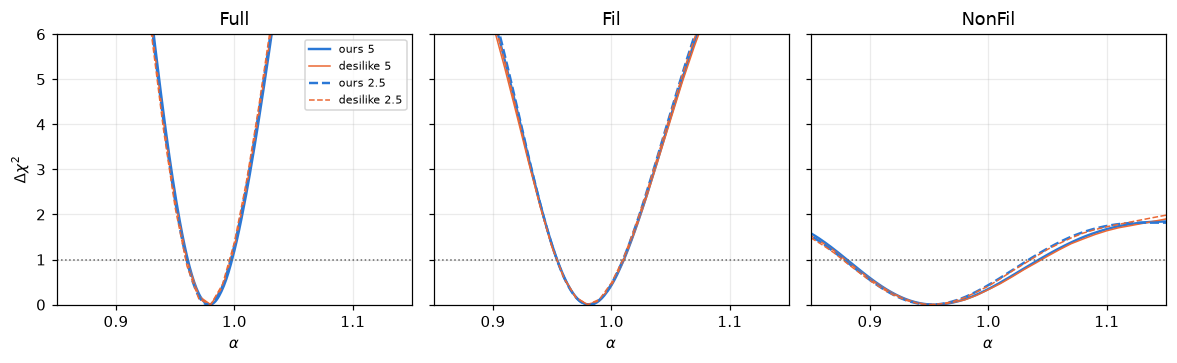

In [10]:
grid = np.linspace(0.85, 1.15, 31)
fig, axes = plt.subplots(1, len(labs_p), figsize=(3.6 * len(labs_p), 3.4), sharey=True, squeeze=False)
for j, lab in enumerate(labs_p):
    ax = axes[0, j]
    for bs, ls in zip(binseps, ('-', '--')):
        if (lab, bs) not in res: continue
        r = res[lab, bs]
        ax.plot(r['ours']['alpha_grid'], r['ours']['prof_alpha'] - r['ours']['prof_alpha'].min(),
                color=OURS, ls=ls, label=f'ours {bs:g}')
        prof = MinuitProfiler(r['lik_a'], seed=42)
        prof.profile(params=['qiso'], grid=grid)
        pr = np.asarray(prof.profiles.profile['qiso'])
        ax.plot(pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max()), color=DESI, ls=ls, lw=1, label=f'desilike {bs:g}')
    ax.axhline(1, color='0.4', ls=':', lw=1); ax.set_xlim(grid[0], grid[-1]); ax.set_ylim(0, 6)
    ax.set_xticks([0.9, 1.0, 1.1])
    ax.set_title(lab); ax.set_xlabel(r'$\alpha$')
axes[0, 0].set_ylabel(r'$\Delta\chi^2$'); axes[0, 0].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 5. Summary table

* α, [68%]: α fit, profile best fit and Δχ² = 1 interval (`open` if it reaches the edge of the α range of
  the fit).
* Σ: Σ fit (flat prior), profile best fit. Ours also gives the marginal mean ⟨Σ⟩ that `run_all`
  quotes; desilike's would need sampling.
* χ²/dof of the α fit, prior term included; dof from `fit_bao`: N_bins + 1 − 6 (the Gaussian Σ prior
  counts as one data point; 6 free parameters α, Σ, B², a₀, a₁, a₂).
* Δχ²_det = χ²(no-wiggle) − χ²(α fit), `run_all` convention.

Below the table: σ_α^Fisher (section 1c, wiggles only) next to the half-width of our α interval at
`binseps[0]`.

In [11]:
def fmt_a(a, lo, hi):
    f = lambda x: 'open' if not np.isfinite(x) else f'{x:.3f}'
    return f"{a:.4f} [{f(lo)}, {f(hi)}]"

hdr = (f"{'sample':<17}{'bin':>4} | {'alpha ours':<25}{'alpha desilike':<25}| {'Sigma o / d  <Sigma> o':<24}"
       f"| {'chi2/dof o / d':<17}| {'dchi2_det o / d':<15}")
print(hdr); print('-' * len(hdr))
for lab in labs:
    for bs in binseps:
        if (lab, bs) not in res: continue
        r = res[lab, bs]; o, oS, dd, dS = r['ours'], r['ours_S'], r['des'], r['des_S']
        dof = r['ours']['dof']
        print(f"{lab:<17}{bs:>4g} | {fmt_a(o['alpha'], o['lo'], o['hi']):<25}"
              f"{fmt_a(dd['pars']['qiso'], dd.get('lo', np.nan), dd.get('hi', np.nan)):<25}| "
              f"{oS['Sigma']:>5.2f} / {dS['pars']['sigmaper']:>5.2f}  {oS['Sigma_marg']['mean']:>5.2f}    | "
              f"{o['chi2_min']:>5.1f} / {r['chi2_d']:>5.1f} /{dof:<3d}| {o['dchi2_wiggle']:>5.2f} / {r['det_d']:>5.2f}")

print()
for lab, sf in sig_fisher.items():
    o = res[lab, bs_ref]['ours']
    print(f"{lab}: Fisher sigma_alpha = {sf:.3f} (wiggles only, Poisson noise);  "
          f"fit half-width at {bs_ref:g} = {0.5 * (o['hi'] - o['lo']):.3f}")

sample            bin | alpha ours               alpha desilike           | Sigma o / d  <Sigma> o  | chi2/dof o / d   | dchi2_det o / d
----------------------------------------------------------------------------------------------------------------------------------------
Full                5 | 0.9790 [0.961, 0.998]    0.9781 [0.960, 0.997]    |  6.49 /  6.25   9.16    |   8.2 /   8.2 /15 | 17.63 / 16.00
Full              2.5 | 0.9780 [0.960, 0.997]    0.9771 [0.959, 0.996]    |  6.18 /  6.10   8.80    |  23.0 /  22.8 /35 | 17.58 / 15.17
Fil                 5 | 0.9816 [0.954, 1.011]    0.9811 [0.954, 1.011]    |  0.00 /  0.11   8.07    |  17.9 /  18.1 /15 |  8.22 /  7.99
Fil               2.5 | 0.9811 [0.954, 1.010]    0.9805 [0.953, 1.010]    |  0.00 /  0.00   8.11    |  31.5 /  31.7 /35 |  8.25 /  8.01
NonFil              5 | 0.9544 [0.880, 1.043]    0.9552 [0.879, 1.045]    |  9.11 /  8.86   9.81    |   9.0 /   9.1 /15 |  1.84 /  1.69
NonFil            2.5 | 0.9513 [0.878, 1.034] 

## 6. What changes with the bin width

Left: α with its 68% interval per sample, every binning and both codes (samples with an open interval are
not drawn). Right: Δχ²_det per sample. Dilutions: see the table in section 5. The binnings use the same
galaxies and the same pairs, so they are strongly correlated: differences between binnings are expected to
be a fraction of the error bar.

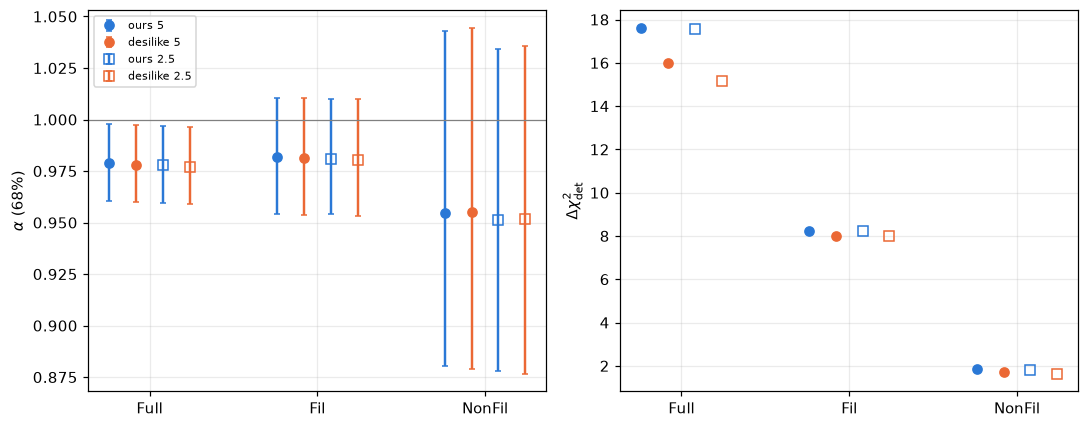

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(labs_p))
for k_, (bs, mk) in enumerate(zip(binseps, ('o', 's'))):
    for c_, (code_, col) in enumerate((('ours', OURS), ('des', DESI))):
        dx = -0.24 + 0.16 * (2 * k_ + c_)
        for j, lab in enumerate(labs_p):
            if (lab, bs) not in res: continue
            r = res[lab, bs]
            if code_ == 'ours':
                a, lo, hi, det = r['ours']['alpha'], r['ours']['lo'], r['ours']['hi'], r['ours']['dchi2_wiggle']
            else:
                a, lo, hi, det = r['des']['pars']['qiso'], r['des'].get('lo', np.nan), r['des'].get('hi', np.nan), r['det_d']
            lbl = f"{'ours' if code_ == 'ours' else 'desilike'} {bs:g}" if j == 0 else None
            if np.isfinite(lo) and np.isfinite(hi):
                a1.errorbar(j + dx, a, yerr=[[a - lo], [hi - a]], fmt=mk, color=col, mfc=col if bs == bs_ref else 'none',
                            capsize=2, label=lbl)
            a2.plot(j + dx, det, mk, color=col, mfc=col if bs == bs_ref else 'none', label=lbl)
for a in (a1, a2):
    a.set_xticks(x); a.set_xticklabels(labs_p)
a1.axhline(1, color='0.5', lw=0.8); a1.set_ylabel(r'$\alpha$ (68%)'); a1.legend(fontsize=7)
a2.set_ylabel(r'$\Delta\chi^2_{\rm det}$'); fig.tight_layout(); plt.show()